# YOLOv11x-OBB Training Metrics Analysis

This notebook visualizes the training and validation metrics generated
during YOLOv11x-OBB training.

The notebook includes:

- Training loss visualization
- Validation loss visualization
- Precision and recall analysis
- mAP evolution across epochs
- Smoothed metric trends using Savitzky-Golay filtering

The metrics are generated from the `results.csv`
file produced during YOLO training.

In [2]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from scipy.signal import savgol_filter

In [3]:
plt.rcParams["figure.figsize"] = (14, 6)
plt.rcParams["font.size"] = 12
plt.rcParams["axes.grid"] = True

In [4]:
CSV_PATH = (
    "../runs/finalModel/"
    "results.csv"
)

df = pd.read_csv(CSV_PATH)

print(f"Loaded {len(df)} epochs.")

Loaded 237 epochs.


In [5]:
df.head()

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,132.660,1.60599,1.51669,2.26139,0.58908,0.77207,0.70973,0.37633,1.64590,1.27691,2.55254,0.070048,0.003328,0.003328
1,2,228.390,1.52805,1.31543,2.19293,0.69277,0.73956,0.75807,0.47114,1.33337,1.34615,2.19502,0.040026,0.006639,0.006639
2,3,320.315,1.46077,1.22069,2.11592,0.77423,0.78981,0.82371,0.52426,1.31242,0.93381,2.23391,0.009982,0.009929,0.009929
3,4,411.841,1.43894,1.24901,2.11140,0.66051,0.85331,0.83326,0.53273,1.24499,0.99909,2.16461,0.009901,0.009901,0.009901
4,5,503.343,1.39443,1.13071,2.09465,0.67997,0.74678,0.77926,0.50454,1.31905,1.05063,2.23892,0.009868,0.009868,0.009868


In [6]:
df.columns.tolist()

['epoch',
 'time',
 'train/box_loss',
 'train/cls_loss',
 'train/dfl_loss',
 'metrics/precision(B)',
 'metrics/recall(B)',
 'metrics/mAP50(B)',
 'metrics/mAP50-95(B)',
 'val/box_loss',
 'val/cls_loss',
 'val/dfl_loss',
 'lr/pg0',
 'lr/pg1',
 'lr/pg2']

In [7]:
if "epoch" not in df.columns:
    raise ValueError(
        "'epoch' column is missing from results.csv"
    )

In [8]:
exclude_cols = {

    "epoch",
    "time",

    "lr/pg0",
    "lr/pg1",
    "lr/pg2"
}

cols_to_plot = [

    col for col in df.columns

    if col not in exclude_cols
]

print("Metrics to plot:\n")

for col in cols_to_plot:
    print(col)

Metrics to plot:

train/box_loss
train/cls_loss
train/dfl_loss
metrics/precision(B)
metrics/recall(B)
metrics/mAP50(B)
metrics/mAP50-95(B)
val/box_loss
val/cls_loss
val/dfl_loss


In [9]:
def smooth_curve(y, window_length=5, polyorder=2):

    if len(y) < window_length:
        return y

    return savgol_filter(
        y,
        window_length=window_length,
        polyorder=polyorder
    )

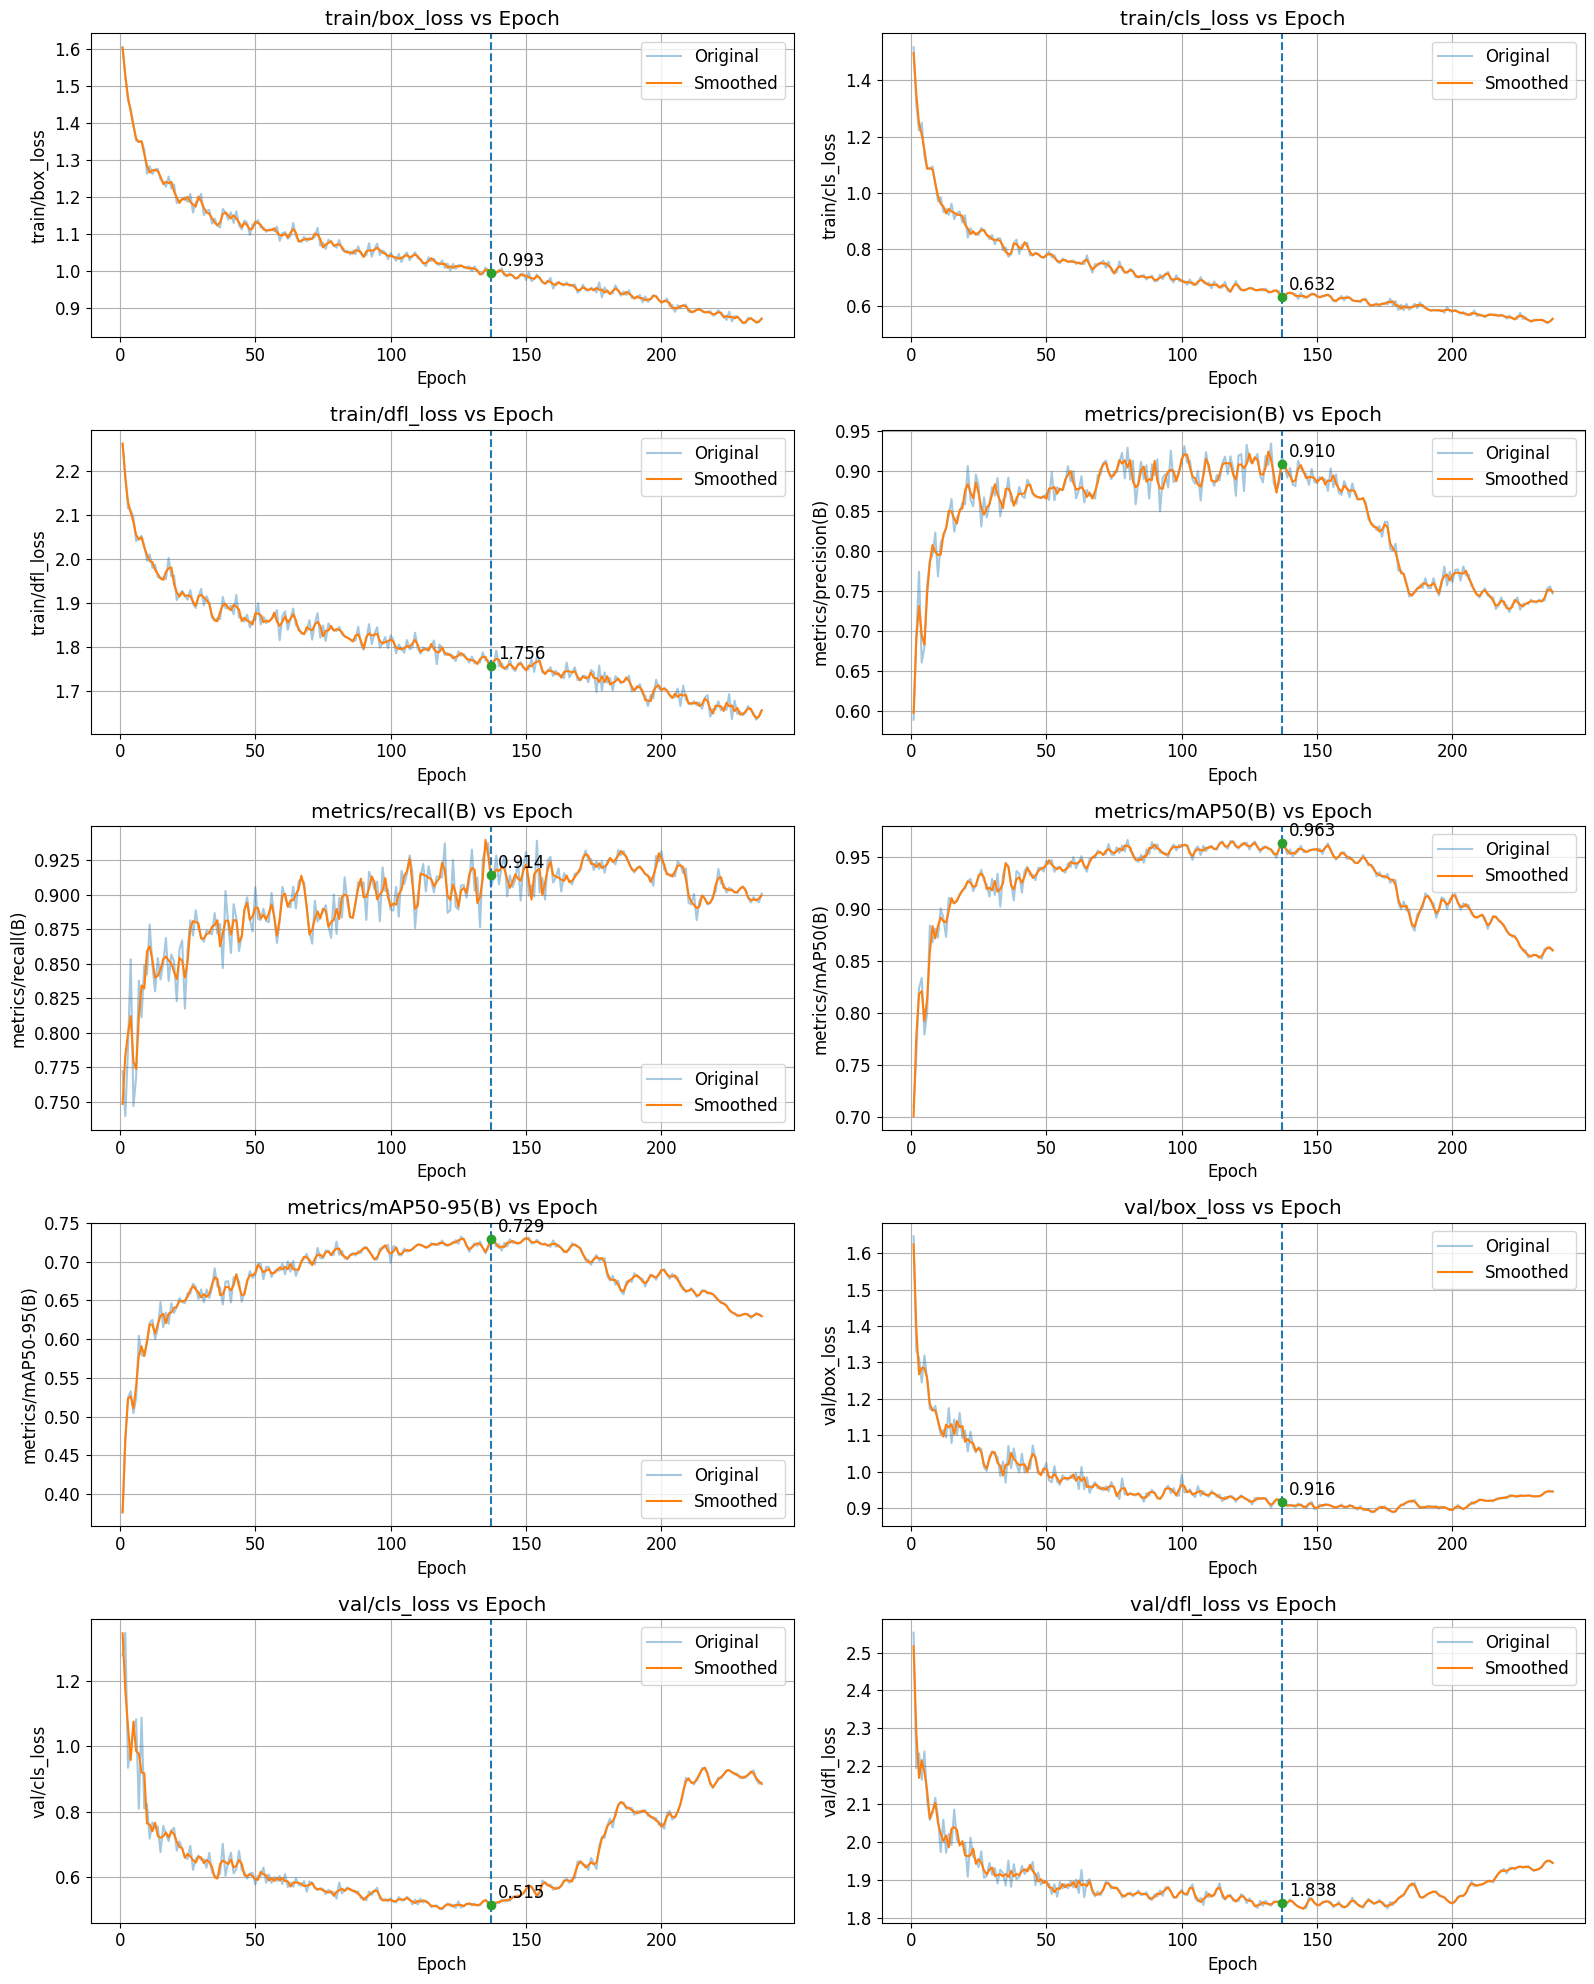

In [10]:
n_plots = len(cols_to_plot)

n_cols = 2

n_rows = (
    n_plots + n_cols - 1
) // n_cols

fig, axs = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, n_rows * 4)
)

axs = axs.flatten()

x = df["epoch"]

TARGET_EPOCH = 137

for i, col in enumerate(cols_to_plot):

    ax = axs[i]

    y = df[col]

    # Original curve
    ax.plot(
        x,
        y,
        label="Original",
        alpha=0.4
    )

    # Smoothed curve
    smoothed_y = smooth_curve(y)

    ax.plot(
        x,
        smoothed_y,
        label="Smoothed"
    )

    # Epoch marker
    if TARGET_EPOCH in x.values:

        epoch_index = (
            x[x == TARGET_EPOCH]
            .index[0]
        )

        y_epoch = smoothed_y[epoch_index]

        ax.axvline(
            TARGET_EPOCH,
            linestyle="--"
        )

        ax.plot(
            TARGET_EPOCH,
            y_epoch,
            marker="o"
        )

        ax.annotate(
            f"{y_epoch:.3f}",
            (
                TARGET_EPOCH,
                y_epoch
            ),
            textcoords="offset points",
            xytext=(5, 5)
        )

    ax.set_title(
        f"{col} vs Epoch"
    )

    ax.set_xlabel("Epoch")

    ax.set_ylabel(col)

    ax.legend()

# Remove unused subplots
for j in range(i + 1, len(axs)):

    fig.delaxes(axs[j])

plt.tight_layout()

plt.show()

In [11]:
metrics_cols = [

    col for col in df.columns

    if "metrics/" in col
]

metrics_cols

['metrics/precision(B)',
 'metrics/recall(B)',
 'metrics/mAP50(B)',
 'metrics/mAP50-95(B)']

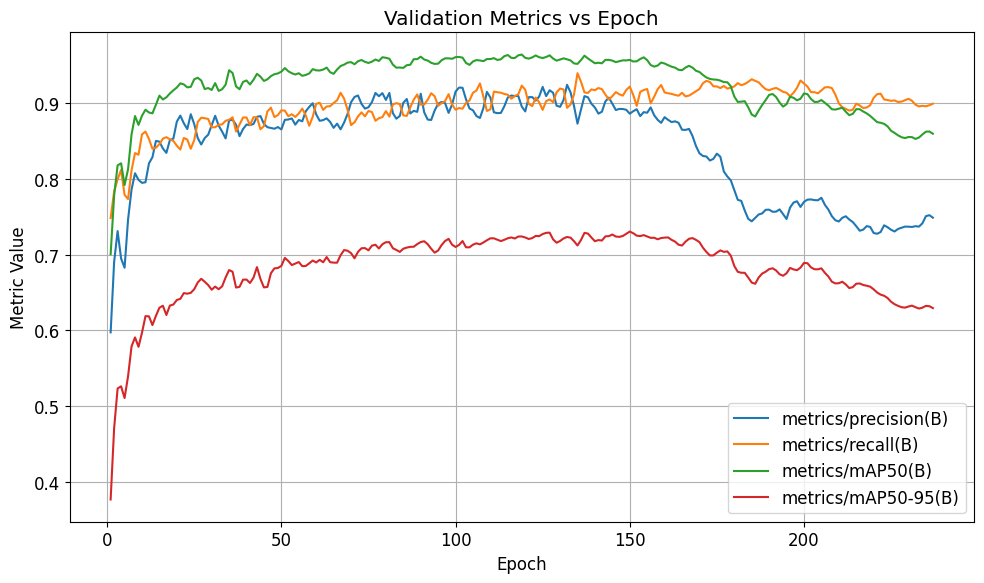

In [12]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = df["epoch"]

for col in metrics_cols:

    y = df[col]

    smoothed_y = smooth_curve(y)

    ax.plot(
        x,
        smoothed_y,
        label=col
    )

ax.set_xlabel("Epoch")

ax.set_ylabel("Metric Value")

ax.set_title(
    "Validation Metrics vs Epoch"
)

ax.legend()

plt.tight_layout()

plt.show()

In [13]:
loss_cols = [

    col for col in df.columns

    if "loss" in col.lower()
]

loss_cols

['train/box_loss',
 'train/cls_loss',
 'train/dfl_loss',
 'val/box_loss',
 'val/cls_loss',
 'val/dfl_loss']

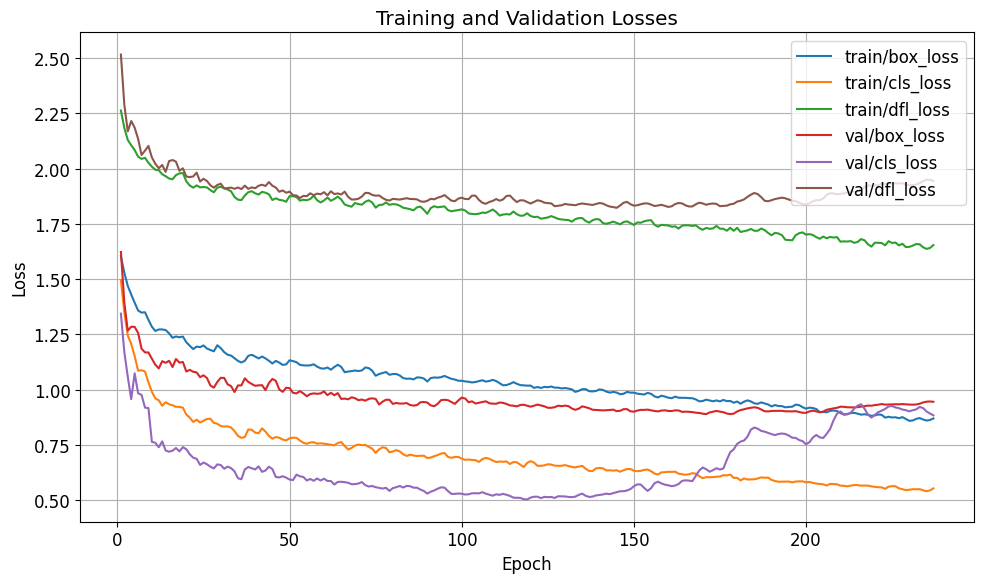

In [14]:
fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = df["epoch"]

for col in loss_cols:

    y = df[col]

    smoothed_y = smooth_curve(y)

    ax.plot(
        x,
        smoothed_y,
        label=col
    )

ax.set_xlabel("Epoch")

ax.set_ylabel("Loss")

ax.set_title(
    "Training and Validation Losses"
)

ax.legend()

plt.tight_layout()

plt.show()

In [15]:
target_metrics = [

    col for col in metrics_cols

    if "mAP50-95" in col
]

target_metrics

['metrics/mAP50-95(B)']

In [16]:
if len(target_metrics) > 0:

    metric_col = target_metrics[0]

    best_idx = df[metric_col].idxmax()

    best_epoch = df.loc[
        best_idx,
        "epoch"
    ]

    best_metric = df.loc[
        best_idx,
        metric_col
    ]

    print(
        f"Best epoch: {best_epoch}"
    )

    print(
        f"Best {metric_col}: "
        f"{best_metric:.4f}"
    )

Best epoch: 137
Best metrics/mAP50-95(B): 0.7325


In [17]:
OUTPUT_DIR = (
    "../docs/figures"
)

os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)

output_path = os.path.join(
    OUTPUT_DIR,
    "yolov11_training_metrics.png"
)

fig.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

print(
    f"Saved figure:\n{output_path}"
)

Saved figure:
../docs/figures\yolov11_training_metrics.png


# Summary

This notebook visualizes and analyzes the YOLOv11x-OBB training
metrics generated during model optimization.

The notebook provides:

- training dynamics visualization
- convergence analysis
- smoothed metric trends
- reproducible publication-quality figures

The generated figures can be directly used for:
- paper plots
- supplementary material
- reproducibility analysis
- training diagnostics